# Музыка Москвы и Петербурга

## Содержание

- [Описание](#section-1)
- [Импорт библиотек Python](#section-2)
- [Загрузка данных](#section-3)
- [Предобработка данных](#section-4)
- [Исследовательский анализ данных](#section-5)
- [Общий вывод](#section-6)

<a id="section-1"></a>

## Описание

На исследовании находятся данные, предоставленные сервисом `Яндекс.Музыка`.

---

**Гипотезы для исследования**

1. Активность пользователей **зависит от дня недели**. Причём в Москве и Петербурге это проявляется по-разному.
2. Утром в понедельник в Москве **преобладают одни жанры музыки**, а в Петербурге — другие. Это верно и для вечера пятницы.
3. Москва и Петербург предпочитают разные жанры музыки. **В Москве чаще слушают поп-музыку, в Петербурге — русский рэп**.

---

**Описание данных**

- **userID** — идентификатор пользователя;
- **Track** — название трека;
- **artist** — имя исполнителя;
- **genre** — название жанра;
- **City** — город пользователя;
- **time** — время начала прослушивания;
- **Day** — день недели.

<a id="section-2"></a>

## Импорт библиотек Python

Данный этап характеризуется следующими последовательными действиями:

1. Импорт библиотек Python для работы над проектом в части:
  * работа с табличными данными:
    * numpy;
    * pandas.
  * визуализация данных:
    * matplotlib;
    * seaborn.
2. Инициализация констант для работы с проектом;
3. Формирование вывода по итогам данного этапа.

In [1]:
# импорт библиотек Python

## работа с табличными данными
## визуализация данных
import os
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
# инициализация переменных проекта

DIR_PATH = os.getcwd()
DATA_DIR = os.environ.get('PORTFOLIO_DATA_DIR', '../data/raw')
DATA_NAME = 'yandex_music_project.csv'

# сборка пути к данным
DATA_PATH = os.path.join(DIR_PATH, DATA_DIR, DATA_NAME)

**Вывод**

1. Импортированы библиотеки Python для работы над проектом в части:
  * работы с табличными данными:
    * numpy;
    * pandas.
  * визуализации данных:
    * matplotlib;
    * seaborn.
2. Инициализированы константы для работы с проектом:
  * **DIR_PATH** - текущая рабочая директория;
  * **DATA_DIR** - директория с хранимыми данными;
  * **DATA_NAME** - название исходного набора данных.

<a id="section-3"></a>

## Загрузка данных

Данный этап характеризуется следующими последовательными действиями:

1. Загрузка набора данных в рабочую среду Jupyter Notebook - инициализация переменной `data`;
2. Инициализация пользовательских функций предварительного обзора набора данных;
3. Вывод на экран основной информации о наборе данных для формирования плана последующих действий;
4. Формирование вывода по итогам данного этапа.

In [3]:
# загрузка данных в рабочую среду
data = pd.read_csv(DATA_PATH)

In [4]:
# инициализация пользовательской функции просмотра пропущенных значений
def na_statistics(df : pd.DataFrame) -> None:
    df_na = df.isna().sum().to_frame()
    df_na.columns = ['na_count']
    df_na['na_share'] = round(df_na['na_count'] / df.shape[0] * 100.0, 2)
    print('Пропущенные значения в наборе данных')
    display(df_na)

In [5]:
# инициализация пользовательской функции просмотра названий признаков и типов данных
def feature_info(df : pd.DataFrame) -> None:
    df_features = df.dtypes.to_frame()
    df_features.columns = ['feature_type']
    print('Названия признаков набора данных и их типы')
    display(df_features)

In [6]:
# инициализация пользовательской функции построения распределений количественных непрерывных показателей
def num_distribution(df : pd.DataFrame, column : str, bins : int):
    plt.subplot(1, 2, 1)
    plt.xlabel(f'Значения признака \n{column}')
    plt.ylabel('Частота значений признака')
    plt.title(f'Гистограмма значений \n{column}', fontsize = 10)
    sns.histplot(data = df, x = df[column], bins = bins)
    plt.subplot(1, 2, 2)
    plt.xlabel(f'Значения признака \n{column}')
    plt.title(f'Диаграмма размаха значений \n{column}', fontsize = 10)
    sns.boxplot(data = df, x = df[column])
    plt.grid(False)
    plt.show()

In [7]:
# вывод на экран общей статистики по пропущенным значениям
na_statistics(data)

Пропущенные значения в наборе данных


,na_count,na_share
userID,0,0.00
Track,1231,1.89
artist,7203,11.07
genre,1198,1.84
City,0,0.00
time,0,0.00
Day,0,0.00


In [8]:
# вывод на экран информации по признакам и их типам
feature_info(data)

Названия признаков набора данных и их типы


,feature_type
userID,object
Track,object
artist,object
genre,object
City,object
time,object
Day,object


In [9]:
# вывод на экран информации о размере данных
print(f'Количество строк в наборе данных: {data.shape[0]}')
print(f'Количество столбцов в наборе данных: {data.shape[1]}')

Количество строк в наборе данных: 65079
Количество столбцов в наборе данных: 7


**Вывод**

1. Выполнена загрузка данных в рабочую среду - инициализирована переменная `data`;
2. Инициализированы пользовательские функции для просмотра первичной информации о наборе данных:
  * na_statistics - для просмотра пустых значений;
  * feature_info - для просмотра названий признаков набора данных и их типов;
  * num_distribution - для просмотра распределения количественных показателей (таких значений в наборе нет).
3. Выведена основная информация о наборе данных:
  * Количество строк - **65_079**, Количество столбцов - **7**;
  * Все признаки имеют тип **object**, строковый тип данных;
  * Имеется **нарушение форматирования snake_case** в названиях признаков;
  * **Имеются пропущенные значения по набору данных**. Самая большая доля - в признаке **artist**.

<a id="section-4"></a>

## Предобработка данных

Данный этап характеризуется следующими последовательными действиями:

1. Преобразование названий столбцов набора данных к формату **snake_case**;
2. Замена пропущенных значений по категориальным признакам;
3. Проверка набора данных на дубликаты (явные и неявные);
4. Преобразование типов данных с учетом семантики значений в столбце;
5. Формирование вывода по итогам данного этапа.

In [10]:
# преобразование названий столбцов датасета
data.columns = data.columns.str.lower().str.strip()
data = data.rename(columns = {'userid' : 'user_id'})

for col in data.columns:
    print(f'* {col}')

* user_id
* track
* artist
* genre
* city
* time
* day


In [11]:
# замена пропущенных значений в категориальных признаках 'artist', 'track'
for col in ['genre', 'artist', 'track']:
    data[col] = data[col].fillna('unknown')

# проверка преобразований
na_statistics(data)

Пропущенные значения в наборе данных


,na_count,na_share
user_id,0,0.0
track,0,0.0
artist,0,0.0
genre,0,0.0
city,0,0.0
time,0,0.0
day,0,0.0


In [12]:
# проверка набора данных на наличие полных дубликатов
print(f'Количество полных дубликатов в наборе: {int(data.duplicated().sum())}')
print(f'Доля полных дубликатов в наборе: {float(data.duplicated().sum() / data.shape[0]):.2%}')

Количество полных дубликатов в наборе: 3826
Доля полных дубликатов в наборе: 5.88%


In [13]:
# исключение полных дубликатов из набора данных
data = data.drop_duplicates().reset_index(drop=True)

In [14]:
# ПОВТОРНАЯ проверка набора данных на наличие полных дубликатов
print(f'Количество полных дубликатов в наборе: {int(data.duplicated().sum())}')
print(f'Доля полных дубликатов в наборе: {float(data.duplicated().sum() / data.shape[0]):.2%}')

Количество полных дубликатов в наборе: 0
Доля полных дубликатов в наборе: 0.00%


In [15]:
# преобразование строковых значений в столбцах 'artist', 'genre', 'track', 'city'
for col in ['artist', 'genre', 'track', 'city']:
    data[col] = data[col].apply(lambda x: x.strip().title())

In [16]:
# вывод уникальных значений столцба 'genre'
genres = pd.DataFrame(
    data=data['genre'].sort_values(ascending = True).unique(),
    columns=['unique_genres']
)
display(genres)

,unique_genres
0,Acid
1,Acoustic
2,Action
3,Adult
4,Africa
...,...
285,Western
286,World
287,Worldbeat
288,Ïîï


**Вывод по промежуточному этапу**

Полный список жанров был изучен с помощью надстройки `DataWrangler`.

Обнаружены неявные дубликаты по столбцу:

* Hip
* Hip-Hop
* Hiphop
* Hop

In [17]:
# инциализация пользовательской функции замены неявных дубликатов я па
def replace_wrong_genres(wrong_genres : list, correct_genre : str) -> pd.Series:
    data['genre'] = data['genre'].replace(wrong_genres, correct_genre)
    return data['genre']

In [18]:
# применение пользовательской функции к набору данных
replace_wrong_genres(['Hip', 'Hiphop', 'Hop'], 'Hip-Hop')

0              Rock
1              Rock
2               Pop
3              Folk
4             Dance
            ...    
61248           Rnb
61249       Hip-Hop
61250    Industrial
61251          Rock
61252       Country
Name: genre, Length: 61253, dtype: object

In [19]:
# вывод на экран жанров, начинающихся на H
mask = data['genre'].str.startswith('H')
display(data[mask]['genre'].unique())

array(['Hip-Hop', 'House', "Hard'N'Heavy", 'Holiday', 'Hardcore',
       'Historisch', 'Hymn', 'Hardstyle', 'Hardtechno', 'Handsup',
       'Horror'], dtype=object)

In [20]:
# проверка значений в столбце 'time'
data['time'].head()

0    20:28:33
1    14:07:09
2    20:58:07
3    08:37:09
4    08:34:34
Name: time, dtype: object

In [21]:
# преобразование значений в столбце 'time' к типу datetime
data['time'] = pd.to_datetime(data['time'], format='%H:%M:%S').dt.time

# проверка преобразования типов
data.dtypes

user_id    object
track      object
artist     object
genre      object
city       object
time       object
day        object
dtype: object

**Вывод**

1. Выполнено преобразование названий столбцов набора данных к формату **snake_case**;
2. Выполнена замена пропущенных значений по признакам **genre**, **artist**, **track** на `unknown`;
3. Выполнено исключение полных дубликатов из набора данных - **исключено 5.9% строк от исходного набора данных**;
4. Выполнена замена значений в признаке **genre** с целью устранения неявных дубликатов - приведение к значению `Hip-Hop`;
5. Выполнено явное преобразование типов данных с учетом семантики значений в столбце - столбец **time**.

<a id="section-5"></a>

## Исследовательский анализ данных

Данный блок характеризуется следующими последовательными действиями:

1. Вывод на экран основной статистической информации о наборе данных;
2. Изучение категориальных показателей набора данных:
  * Динамика прослушиваний треков и активность пользователей в **зависимости от города и дня недели**;
  * Динамика прослушиваний треков и активность пользователей в **зависимости от города и времени дня**;
  * Тестирование гипотезы о жанровых предпочтениях в разных городах.
3. Формирование вывода по итогам данного этапа.

In [22]:
# вывод на экран основной статистичекой информации
print('Основная статистическая информация по набору данных')
data.describe(include="all")

Основная статистическая информация по набору данных


,user_id,track,artist,genre,city,time,day
count,61253,61253,61253,61253,61253,61253,61253
unique,41748,46647,43567,287,2,20392,3
top,A8AE9169,Unknown,Unknown,Pop,Moscow,08:14:07,Friday
freq,71,1159,6772,8323,42741,13,21840


In [23]:
# построение сводной таблицы количества прослушанных треков по городам и дням недели
def day_city_tracks_info(value_col : str, function, feature : str) -> None:
    days = ['Monday', 'Wednesday', 'Friday']

    city_day_pivot = data.pivot_table(
        values = value_col,
        index = 'city',
        columns = 'day',
        aggfunc = function
    ).reindex(columns = days)

    city_day_pivot[f'total_{feature}'] = city_day_pivot.sum(axis = 1)

    display(city_day_pivot)

    plot_data = city_day_pivot.reset_index().melt(
        id_vars='city',
        value_vars=days,
        var_name='day',
        value_name='value',
    )

    ax = sns.barplot(
    data=plot_data,
    x='day',
    y='value',
    hue='city',
    order=days,
    )
    
    ax.set(xlabel='weekday', ylabel=feature)
    ax.legend(title='Город', alignment = 'center', loc='center left', bbox_to_anchor=(1.02, 0.5))
    plt.show()

day,Monday,Wednesday,Friday,total_tracks
city,,,,
Moscow,15740,11056,15945,42741
Saint-Petersburg,5614,7003,5895,18512


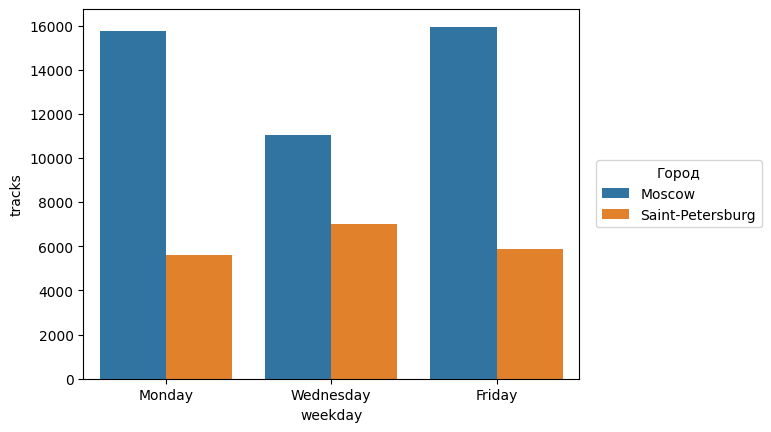

In [24]:
# вывод информации о количестве прослушанных треков
day_city_tracks_info('user_id', 'count', 'tracks')

day,Monday,Wednesday,Friday,total_tracks
city,,,,
Moscow,11904,8388,12145,32437
Saint-Petersburg,4248,5228,4495,13971


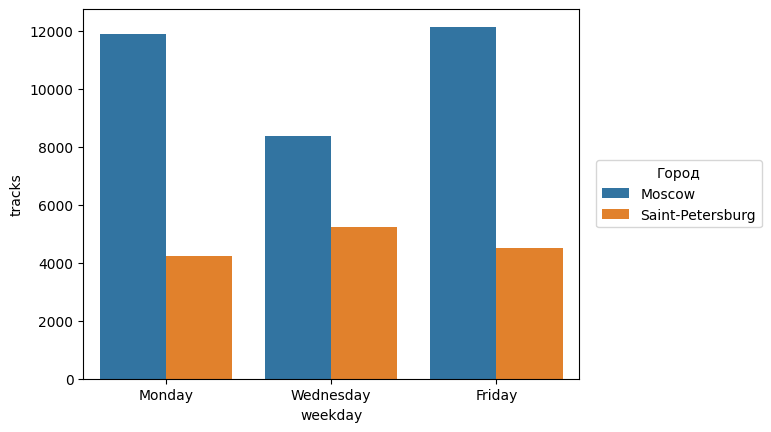

In [25]:
# вывод информации о количестве уникальных пользователей по городам
day_city_tracks_info('user_id', pd.Series.nunique, 'tracks')

In [26]:
# формирование сводных таблиц

tracks = pd.DataFrame(
    data = [
        ['Moscow', 15740, 11056, 15945],
        ['Saint-Petersburg', 5614, 7003, 5895]
        ],
    columns = ['city', 'monday', 'wednesday', 'friday']
)

users = pd.DataFrame(
    data = [
        ['Moscow', 11904, 8388, 12145],
        ['Saint-Petersburg', 4248, 5228, 4495]
        ],
    columns = ['city', 'monday', 'wednesday', 'friday']
)

tracks_users_info = (
    tracks.merge(users, how = 'left', on ='city', suffixes = ['_tracks', '_users'])
)

# формирование датафрейма с удельным количеством прослушанных треков на уникального пользователя - tracks_per_user
tpu_info = pd.DataFrame(
    {
        'city' : ['Moscow','Saint-Petersburg'],
        'monday_tpu' : round(tracks_users_info['monday_tracks'] / tracks_users_info['monday_users'], 1),
        'wednesday_tpu' : round(tracks_users_info['wednesday_tracks'] / tracks_users_info['wednesday_users'], 1),
        'friday_tpu' : round(tracks_users_info['friday_tracks'] / tracks_users_info['friday_users'], 1),
    }
)

display(tpu_info)

,city,monday_tpu,wednesday_tpu,friday_tpu
0,Moscow,1.3,1.3,1.3
1,Saint-Petersburg,1.3,1.3,1.3


**Вывод по промежуточному этапу**

* **Больше всего треков (агрегированная сумма) прослушивается в Москве - 42 741** против 18 512 в Петербурге;
* Динамика прослушивания треков:
  * Москва: Пики приходятся на начало и конец рабочей недели - понедельник и пятница;
  * Санкт-Петербург: Пик прослушиваний достигается в среду;
* Удельное количество треков на пользователя в каждый день недели и по каждому городу равно 1.3.

In [27]:
# инициализация перменных для хранения информации по каждому городу

moscow_general = data[data['city'] == 'Moscow']
spb_general = data[data['city'] == 'Saint-Petersburg']

In [28]:
# инициализация пользовательской функции формирования отчета по статистике жанров во временной промежуток


def genre_weekday(df : pd.DataFrame, weekday : str, time1 : str, time2 : str, city_title : str) -> None:

    start_time = datetime.strptime(time1, '%H:%M').time()
    end_time = datetime.strptime(time2, '%H:%M').time()

    mask = (
        df['day'].eq(weekday)
        & df['time'].ge(start_time)
        & df['time'].lt(end_time)
    )

    df_filtered = df.loc[mask]

    genre_pivot = df_filtered.groupby('genre').agg({'track' : 'count'}).sort_values(by = 'track', ascending = False).head(10)
    genre_pivot.columns = ['total_tracks']
    display(genre_pivot)

    plt.figure(figsize=(12, 5))
    ax = sns.barplot(
        genre_pivot,
        x = 'genre',
        y = 'total_tracks'
        
    )
    ax.set(xlabel='genres', ylabel='total_tracks', title = f'Самые популярные жанры в городе {city_title}')
    plt.xticks(rotation = 45)
    plt.show()

,total_tracks
genre,
Pop,781
Dance,549
Electronic,480
Rock,474
Hip-Hop,286
Ruspop,186
World,181
Rusrap,175
Alternative,164


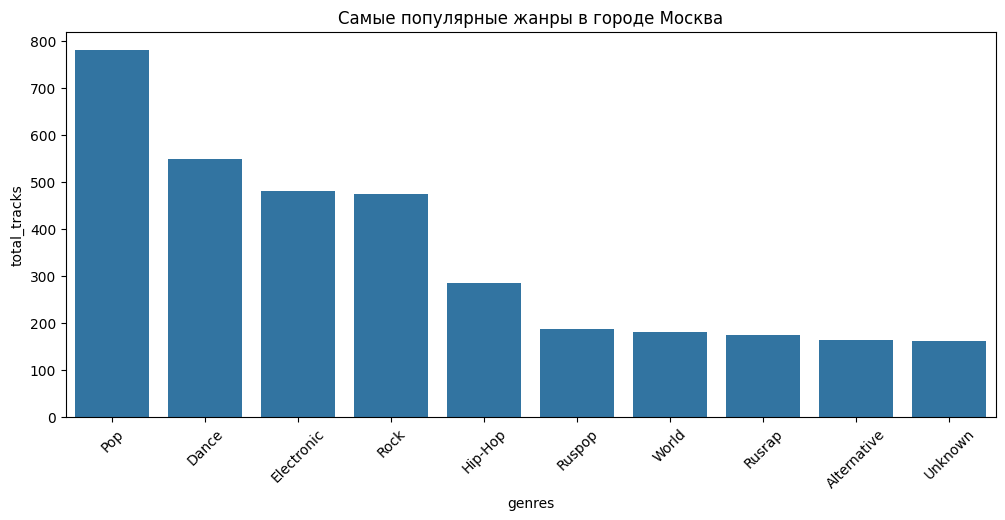

In [29]:
# вывод информации о популярных жанрах в Москве утром понедельника
genre_weekday(moscow_general, 'Monday', '07:00', '11:00', 'Москва')

,total_tracks
genre,
Pop,218
Dance,182
Rock,162
Electronic,147
Hip-Hop,80
Ruspop,64
Alternative,58
Rusrap,55
Jazz,44


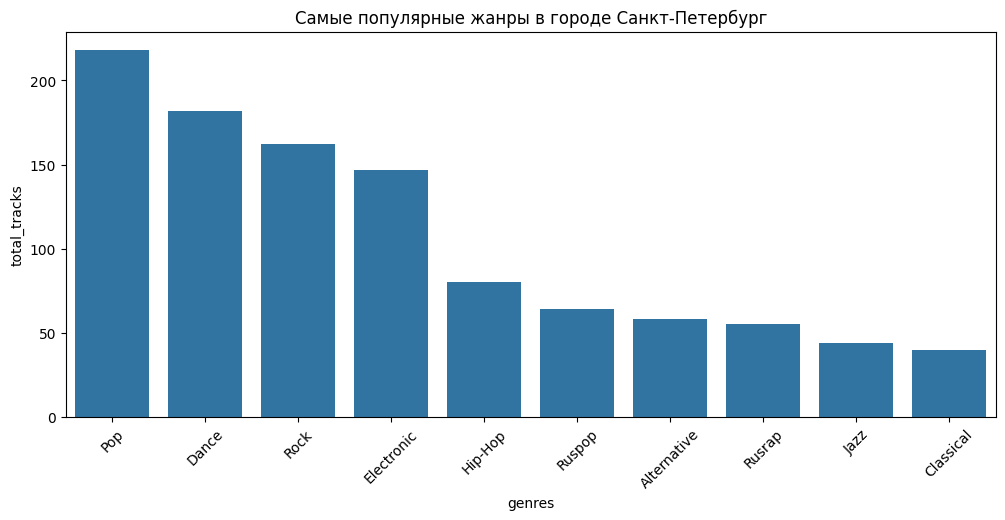

In [30]:
# вывод информации о популярных жанрах в СпБ утром понедельника
genre_weekday(spb_general, 'Monday', '07:00', '11:00', 'Санкт-Петербург')

,total_tracks
genre,
Pop,713
Rock,517
Dance,495
Electronic,482
Hip-Hop,273
World,208
Ruspop,170
Alternative,163
Classical,163


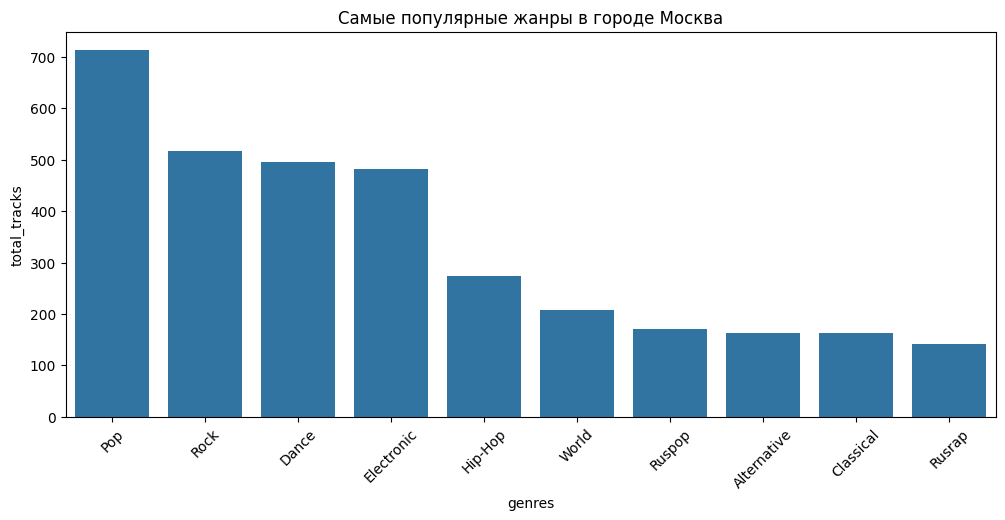

In [31]:
# вывод информации о популярных жанрах в Москве в вечер пятницы
genre_weekday(moscow_general, 'Friday', '17:00', '23:00', 'Москва')

,total_tracks
genre,
Pop,256
Electronic,216
Rock,216
Dance,210
Hip-Hop,97
Alternative,63
Jazz,61
Classical,60
Rusrap,59


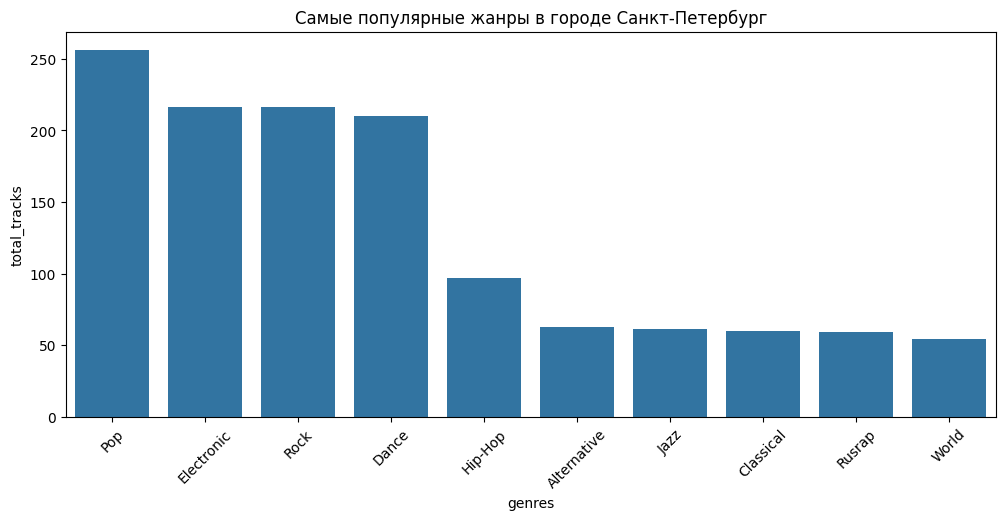

In [32]:
# вывод информации о популярных жанрах в СпБ в вечер пятницы
genre_weekday(spb_general, 'Friday', '17:00', '23:00', 'Санкт-Петербург')

**Вывод по промежуточному этапу**

* В Москве и Петербурге слушают похожую музыку. Единственное отличие — в московский рейтинг вошёл жанр `world`, а в петербургский — `jazz` и `classical`;
* В Москве пропущенных значений оказалось так много, что значение `unknown` заняло десятое место среди самых популярных жанров. Значит, пропущенные значения занимают существенную долю в данных и угрожают достоверности исследования.
* Вечер пятницы не меняет эту картину. Некоторые жанры поднимаются немного выше, другие спускаются, но в целом топ-10 остаётся тем же самым.
* Пользователи слушают похожую музыку в начале недели и в конце.
* Разница между Москвой и Петербургом не слишком выражена. В Москве чаще слушают русскую популярную музыку, в Петербурге — джаз.

Однако пропуски в данных ставят под сомнение этот результат. В Москве их так много, что рейтинг топ-10 мог бы выглядеть иначе, если бы не утерянные  данные о жанрах.

### Жанровые предпочтения в Москве и Петербурге

Гипотеза: Петербург — столица рэпа, музыку этого жанра там слушают чаще, чем в Москве.  А Москва — город контрастов, в котором, тем не менее, преобладает поп-музыка.

Сгруппируйте таблицу `moscow_general` по жанру и посчитайте прослушивания треков каждого жанра методом `count()`. Затем отсортируйте результат в порядке убывания и сохраните его в таблице `moscow_genres`.

In [33]:
# построение сводной таблицы по жанрам в Москве
moscow_genres = (
    moscow_general.groupby('genre')
    .agg({'user_id' : 'count'})
    .sort_values(by = 'user_id', ascending = False)
    .rename(columns = {'user_id' : 'total_tracks'})
)

# вывод на экран топ-10
moscow_genres.head(10)

,total_tracks
genre,
Pop,5892
Dance,4435
Rock,3965
Electronic,3786
Hip-Hop,2096
Classical,1616
World,1432
Alternative,1379
Ruspop,1372


In [34]:
# построение сводной таблицы по жанрам в Москве
spb_genres = (
    spb_general.groupby('genre')
    .agg({'user_id' : 'count'})
    .sort_values(by = 'user_id', ascending = False)
    .rename(columns = {'user_id' : 'total_tracks'})
)

# вывод на экран топ-10
spb_genres.head(10)

,total_tracks
genre,
Pop,2431
Dance,1932
Rock,1879
Electronic,1736
Hip-Hop,960
Alternative,649
Classical,646
Rusrap,564
Ruspop,538


**Вывод по промежуточному этапу**

* Поп-музыка — самый популярный жанр в Москве, как и предполагала гипотеза. Более того, в топ-10 жанров встречается близкий жанр — русская популярная музыка;
* Вопреки ожиданиям, рэп одинаково популярен в Москве и Петербурге.

**Вывод**

1. Выведена основная информация о наборе данных;
2. Проведено изучение категориальных показателей набора данных:
    * Динамика прослушиваний треков и активность пользователей в **зависимости от города и дня недели**:
        * **Больше всего треков (агрегированная сумма) прослушивается в Москве - 42 741** против 18 512 в Петербурге;
        * Динамика прослушивания треков:
            * Москва: Пики приходятся на начало и конец рабочей недели - понедельник и пятница;
            * Санкт-Петербург: Пик прослушиваний достигается в среду;
        * Удельное количество треков на пользователя в каждый день недели и по каждому городу равно 1.3.
    * Динамика прослушиваний треков и активность пользователей в **зависимости от города и времени дня**:
        * В Москве и Петербурге слушают похожую музыку. Единственное отличие — в московский рейтинг вошёл жанр `world`, а в петербургский — `jazz` и `classical`;
        * В Москве пропущенных значений оказалось так много, что значение `unknown` заняло десятое место среди самых популярных жанров. Значит, пропущенные значения занимают существенную долю в данных и угрожают достоверности исследования.
        * Вечер пятницы не меняет эту картину. Некоторые жанры поднимаются немного выше, другие спускаются, но в целом топ-10 остаётся тем же самым.
        * Пользователи слушают похожую музыку в начале недели и в конце.
        * Разница между Москвой и Петербургом не слишком выражена. В Москве чаще слушают русскую популярную музыку, в Петербурге — джаз.
    * Тестирование гипотезы о жанровых предпочтениях в разных городах:
        * Поп-музыка — самый популярный жанр в Москве, как и предполагала гипотеза. Более того, в топ-10 жанров встречается близкий жанр — русская популярная музыка;
        * Вопреки ожиданиям, рэп одинаково популярен в Москве и Петербурге.

<a id="section-6"></a>

## Общий вывод

1. Импортированы библиотеки Python для работы над проектом в части:
  * работы с табличными данными:
    * numpy;
    * pandas.
  * визуализации данных:
    * matplotlib;
    * seaborn.
2. Инициализированы константы для работы с проектом:
  * **DIR_PATH** - текущая рабочая директория;
  * **DATA_DIR** - директория с хранимыми данными;
  * **DATA_NAME** - название исходного набора данных.
3. Выполнена загрузка данных в рабочую среду - инициализирована переменная `data`;
4. Инициализированы пользовательские функции для просмотра первичной информации о наборе данных:
  * na_statistics - для просмотра пустых значений;
  * feature_info - для просмотра названий признаков набора данных и их типов;
  * num_distribution - для просмотра распределения количественных показателей (таких значений в наборе нет).
5. Выведена основная информация о наборе данных:
  * Количество строк - **65_079**, Количество столбцов - **7**;
  * Все признаки имеют тип **object**, строковый тип данных;
  * Имеется **нарушение форматирования snake_case** в названиях признаков;
  * **Имеются пропущенные значения по набору данных**. Самая большая доля - в признаке **artist**.
6. Выполнено преобразование названий столбцов набора данных к формату **snake_case**;
7. Выполнена замена пропущенных значений по признакам **genre**, **artist**, **track** на `unknown`;
8. Выполнено исключение полных дубликатов из набора данных - **исключено 5.9% строк от исходного набора данных**;
9. Выполнена замена значений в признаке **genre** с целью устранения неявных дубликатов - приведение к значению `Hip-Hop`;
10. Выполнено явное преобразование типов данных с учетом семантики значений в столбце - столбец **time**.
11. Выведена основная информация о наборе данных;
12. Проведено изучение категориальных показателей набора данных:
  * Динамика прослушиваний треков и активность пользователей в **зависимости от города и дня недели**:
      * **Больше всего треков (агрегированная сумма) прослушивается в Москве - 42 741** против 18 512 в Петербурге;
      * Динамика прослушивания треков:
          * Москва: Пики приходятся на начало и конец рабочей недели - понедельник и пятница;
          * Санкт-Петербург: Пик прослушиваний достигается в среду;
      * Удельное количество треков на пользователя в каждый день недели и по каждому городу равно 1.3.
  * Динамика прослушиваний треков и активность пользователей в **зависимости от города и времени дня**:
      * В Москве и Петербурге слушают похожую музыку. Единственное отличие — в московский рейтинг вошёл жанр `world`, а в петербургский — `jazz` и `classical`;
      * В Москве пропущенных значений оказалось так много, что значение `unknown` заняло десятое место среди самых популярных жанров. Значит, пропущенные значения занимают существенную долю в данных и угрожают достоверности исследования.
      * Вечер пятницы не меняет эту картину. Некоторые жанры поднимаются немного выше, другие спускаются, но в целом топ-10 остаётся тем же самым.
      * Пользователи слушают похожую музыку в начале недели и в конце.
      * Разница между Москвой и Петербургом не слишком выражена. В Москве чаще слушают русскую популярную музыку, в Петербурге — джаз.
  * Тестирование гипотезы о жанровых предпочтениях в разных городах:
      * Поп-музыка — самый популярный жанр в Москве, как и предполагала гипотеза. Более того, в топ-10 жанров встречается близкий жанр — русская популярная музыка;
      * Вопреки ожиданиям, рэп одинаково популярен в Москве и Петербурге.